In [4]:
import pandas as pd
import numpy as np
import seaborn as sns

In [5]:
data = pd.read_csv("Airbnb_Open_Data.csv", engine="python", on_bad_lines="skip")

In [6]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 102599 entries, 0 to 102598
Data columns (total 26 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   id                              102599 non-null  int64  
 1   NAME                            102349 non-null  str    
 2   host id                         102599 non-null  int64  
 3   host_identity_verified          102310 non-null  str    
 4   host name                       102193 non-null  str    
 5   neighbourhood group             102570 non-null  str    
 6   neighbourhood                   102583 non-null  str    
 7   lat                             102591 non-null  float64
 8   long                            102591 non-null  float64
 9   country                         102067 non-null  str    
 10  country code                    102468 non-null  str    
 11  instant_bookable                102494 non-null  object 
 12  cancellation_policy        

In [7]:
data.columns

Index(['id', 'NAME', 'host id', 'host_identity_verified', 'host name',
       'neighbourhood group', 'neighbourhood', 'lat', 'long', 'country',
       'country code', 'instant_bookable', 'cancellation_policy', 'room type',
       'Construction year', 'price', 'service fee', 'minimum nights',
       'number of reviews', 'last review', 'reviews per month',
       'review rate number', 'calculated host listings count',
       'availability 365', 'house_rules', 'license'],
      dtype='str')

In [8]:
data.drop(columns='license',inplace=True)

In [9]:
data.head(1)

,id,NAME,host id,host_identity_verified,host name,neighbourhood group,neighbourhood,lat,long,country,...,price,service fee,minimum nights,number of reviews,last review,reviews per month,review rate number,calculated host listings count,availability 365,house_rules
0,1001254,Clean & quiet apt home by the park,80014485718,unconfirmed,Madaline,Brooklyn,Kensington,40.64749,-73.97237,United States,...,$966,$193,10.0,9.0,10/19/2021,0.21,4.0,6.0,286.0,Clean up and treat the home the way you'd like...


In [10]:
data.columns

Index(['id', 'NAME', 'host id', 'host_identity_verified', 'host name',
       'neighbourhood group', 'neighbourhood', 'lat', 'long', 'country',
       'country code', 'instant_bookable', 'cancellation_policy', 'room type',
       'Construction year', 'price', 'service fee', 'minimum nights',
       'number of reviews', 'last review', 'reviews per month',
       'review rate number', 'calculated host listings count',
       'availability 365', 'house_rules'],
      dtype='str')

In [11]:
drop_data = ['reviews per month',
             'review rate number',
             'calculated host listings count',
             'availability 365',
             'house_rules','id']

skip_data = ['NAME',
             'host id',
             'host_identity_verified',
             'host name',
             'neighbourhood group',
             'neighbourhood',
             'lat', 'long', 'country',
             'country code', 'instant_bookable',
             'cancellation_policy',
             'room type',
             'Construction year', 'price',
             'service fee', 'minimum nights',
            'number of reviews', 'last review']

In [12]:
len(skip_data)

19

In [13]:
df=data[skip_data]

In [14]:
data.drop(columns=drop_data,inplace=True)

In [15]:
data.shape

(102599, 19)

In [16]:
# change name
new_columns = []
for i in data.columns:
    new_columns.append(i.upper())

In [17]:
new_columns

['NAME',
 'HOST ID',
 'HOST_IDENTITY_VERIFIED',
 'HOST NAME',
 'NEIGHBOURHOOD GROUP',
 'NEIGHBOURHOOD',
 'LAT',
 'LONG',
 'COUNTRY',
 'COUNTRY CODE',
 'INSTANT_BOOKABLE',
 'CANCELLATION_POLICY',
 'ROOM TYPE',
 'CONSTRUCTION YEAR',
 'PRICE',
 'SERVICE FEE',
 'MINIMUM NIGHTS',
 'NUMBER OF REVIEWS',
 'LAST REVIEW']

In [18]:
new_dataframe = data.copy()
new_dataframe.columns = new_columns
new_dataframe.head(2)


,NAME,HOST ID,HOST_IDENTITY_VERIFIED,HOST NAME,NEIGHBOURHOOD GROUP,NEIGHBOURHOOD,LAT,LONG,COUNTRY,COUNTRY CODE,INSTANT_BOOKABLE,CANCELLATION_POLICY,ROOM TYPE,CONSTRUCTION YEAR,PRICE,SERVICE FEE,MINIMUM NIGHTS,NUMBER OF REVIEWS,LAST REVIEW
0,Clean & quiet apt home by the park,80014485718,unconfirmed,Madaline,Brooklyn,Kensington,40.64749,-73.97237,United States,US,False,strict,Private room,2020.0,$966,$193,10.0,9.0,10/19/2021
1,Skylit Midtown Castle,52335172823,verified,Jenna,Manhattan,Midtown,40.75362,-73.98377,United States,US,False,moderate,Entire home/apt,2007.0,$142,$28,30.0,45.0,5/21/2022


In [19]:

data.duplicated().sum()
data.drop_duplicates(inplace=True)
data.duplicated().sum()

np.int64(0)

In [20]:
data.dropna(how='all', inplace=True)
data.isnull().sum()

NAME                        250
host id                       0
host_identity_verified      289
host name                   404
neighbourhood group          29
neighbourhood                16
lat                           8
long                          8
country                     532
country code                131
instant_bookable            105
cancellation_policy          76
room type                     0
Construction year           214
price                       247
service fee                 273
minimum nights              400
number of reviews           183
last review               15832
dtype: int64

In [21]:
data.drop(columns=['last review'],inplace=True)


In [22]:
data = data.replace(r'^\s*$', np.nan, regex=True)
data.dropna(how='all', inplace=True)


In [23]:
data.dropna(inplace=True)

In [24]:
data.isna().sum()

NAME                      0
host id                   0
host_identity_verified    0
host name                 0
neighbourhood group       0
neighbourhood             0
lat                       0
long                      0
country                   0
country code              0
instant_bookable          0
cancellation_policy       0
room type                 0
Construction year         0
price                     0
service fee               0
minimum nights            0
number of reviews         0
dtype: int64

In [25]:
data['host_identity_verified']=data['host_identity_verified'].str.upper()

In [26]:
data['instant_bookable']=data['instant_bookable'].apply(lambda x: 1 if x == True else 0)

In [27]:
data.head()
data.reset_index(inplace=True)
data.head(1)

,index,NAME,host id,host_identity_verified,host name,neighbourhood group,neighbourhood,lat,long,country,country code,instant_bookable,cancellation_policy,room type,Construction year,price,service fee,minimum nights,number of reviews
0,0,Clean & quiet apt home by the park,80014485718,UNCONFIRMED,Madaline,Brooklyn,Kensington,40.64749,-73.97237,United States,US,0,strict,Private room,2020.0,$966,$193,10.0,9.0


In [28]:
import re

In [29]:
import re
data['price']
data['price']=data['price'].str.replace("$","")
data['service fee']=data['service fee'].str.replace("$","")
data['price'] = data['price'].str.replace(r'[\s,]', '', regex=True)

In [30]:
data['price'] = pd.to_numeric(data['price'], errors='coerce')
data['service fee'] = pd.to_numeric(data['service fee'], errors='coerce')

In [31]:
type(data['price'][1])
data['price'] = data['price'].astype('int32')

In [32]:
type(data['price'][1])

numpy.int32

In [33]:
data['service fee']=data['service fee'].astype('int32')
type(data['service fee'][15])

numpy.int32

In [34]:
data['Construction year']
data['Construction year'] = data['Construction year'].astype('Int64')
# data['Construction year'] = data['Construction year'].astype(str).str.replace('0', '', regex=False)

In [35]:
data.drop(columns=['index'], inplace=True)

In [36]:
data.drop(columns=['Unnamed: 0', 'level_0', 'index'], inplace=True, errors='ignore')

In [37]:
text_cols = data.select_dtypes(include='object').columns

for col in text_cols:
    data[col] = data[col].str.strip()

C:\Users\dell\AppData\Local\Temp\ipykernel_16708\4170328207.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  text_cols = data.select_dtypes(include='object').columns


In [38]:
data['minimum nights'] = data['minimum nights'].astype('Int64')

In [39]:
data['number of reviews'] = data['number of reviews'].astype('Int64')

In [40]:
data['Construction year']

0        2020
1        2007
2        2009
3        2013
4        2009
         ... 
99337    2018
99338    2015
99339    2020
99340    2007
99341    2022
Name: Construction year, Length: 99342, dtype: Int64

In [41]:
data.columns

Index(['NAME', 'host id', 'host_identity_verified', 'host name',
       'neighbourhood group', 'neighbourhood', 'lat', 'long', 'country',
       'country code', 'instant_bookable', 'cancellation_policy', 'room type',
       'Construction year', 'price', 'service fee', 'minimum nights',
       'number of reviews'],
      dtype='str')

<Axes: >

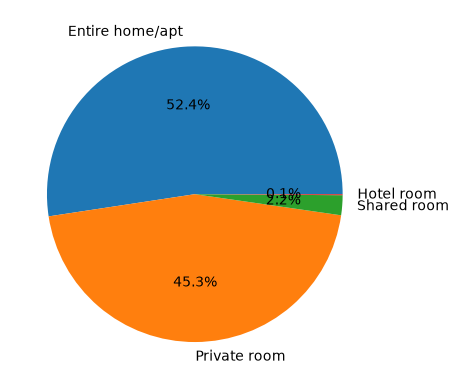

In [43]:
data['room type'].value_counts().plot(kind='pie',autopct='%1.1f%%')

<Axes: xlabel='room type'>

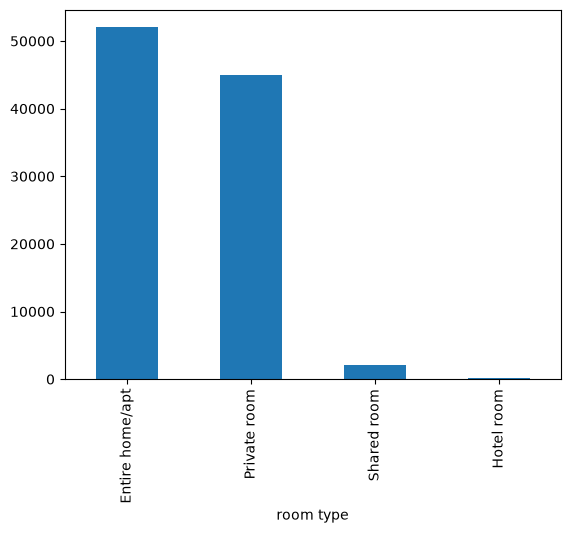

In [46]:
data['room type'].value_counts().plot(kind='bar')

<Axes: xlabel='neighbourhood group'>

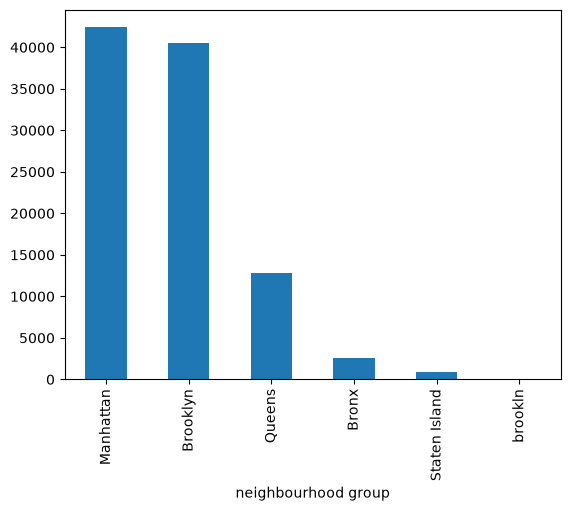

In [47]:
data['neighbourhood group'].value_counts().plot(kind='bar')

<Axes: >

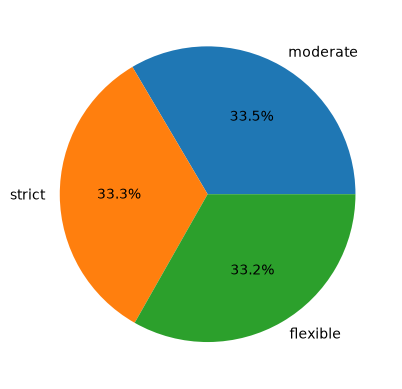

In [49]:
data['cancellation_policy'].value_counts().plot(kind='pie',autopct='%1.1f%%')

<Axes: >

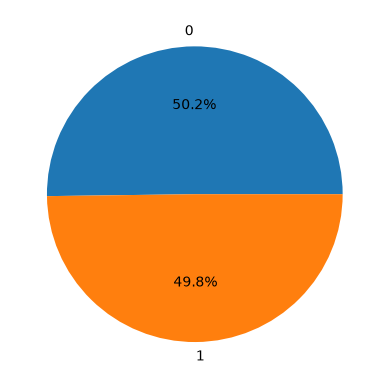

In [50]:
data['instant_bookable'].value_counts().plot(kind='pie',autopct='%1.1f%%')

<Axes: xlabel='Construction year'>

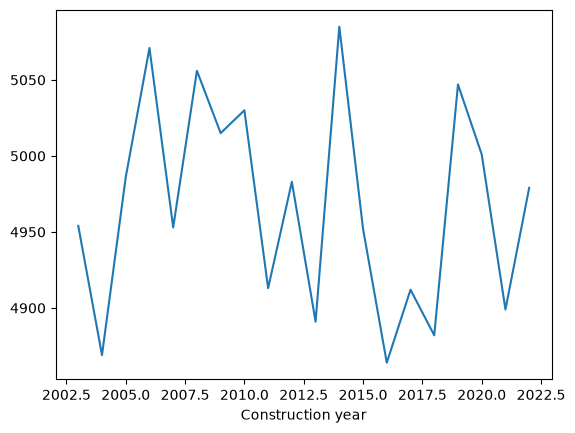

In [51]:
data['Construction year'].value_counts().sort_index().plot(kind='line')

<Axes: ylabel='Frequency'>

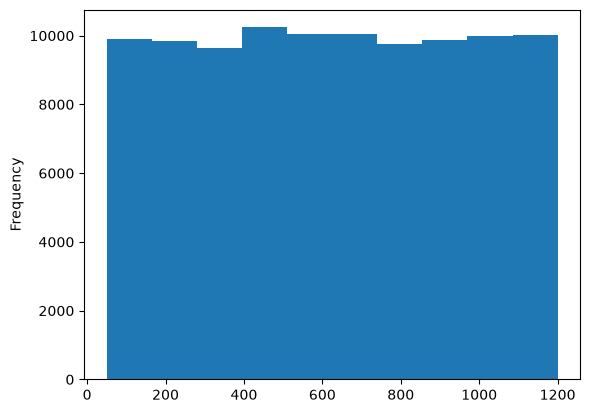

In [53]:
data['price'] = pd.to_numeric(data['price'], errors='coerce')
data['price'].plot(kind='hist')

<Axes: xlabel='number of reviews', ylabel='price'>

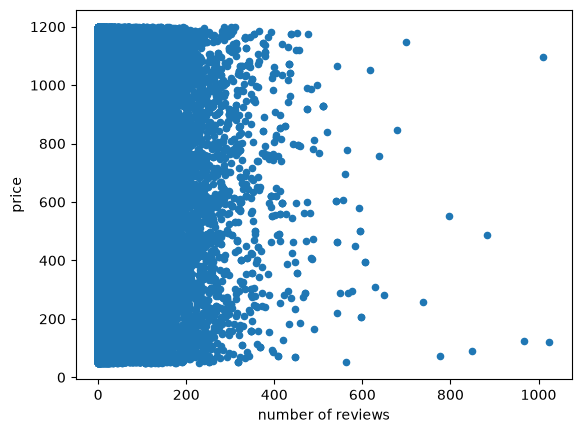

In [57]:
data.plot(x='number of reviews', y='price', kind='scatter')

<Axes: xlabel='room type'>

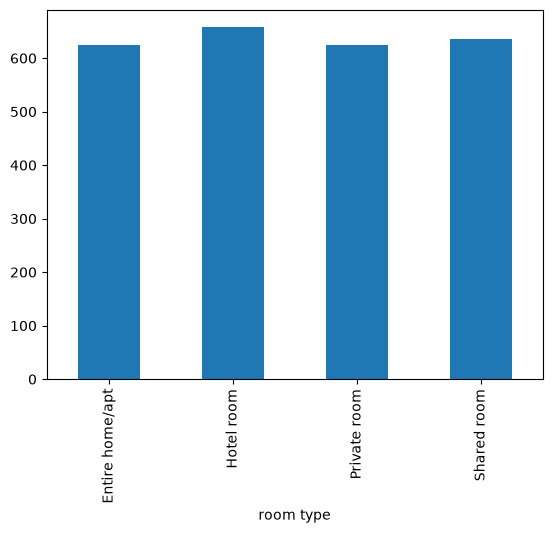

In [58]:
data.groupby('room type')['price'].mean().plot(kind='bar')

<Axes: >

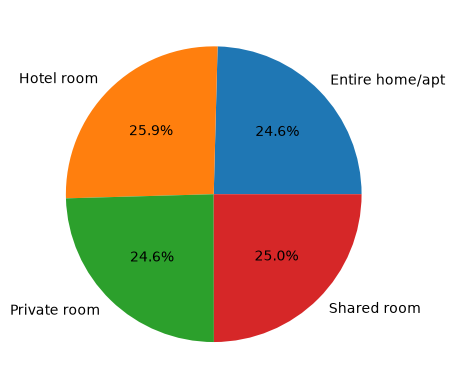

In [59]:
data.groupby('room type')['price'].mean().plot(kind='pie',autopct='%1.1f%%')

In [ ]:
data['minimum nights'].plot(kind='bar')

In [ ]:
data['number of reviews'].plot(kind='hist')